**Connect to Google Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np

project_path = "/content/drive/MyDrive/Financial_Fraud_Project"

print("Project folder exists:", os.path.exists(project_path))
print("Project files:", os.listdir(project_path))

Mounted at /content/drive
Project folder exists: True
Project files: ['gnn_predictions.csv', 'transactions.csv', 'rf_xgb_predictions.csv', 'app.py.backup', 'xgboost_model.pkl', 'gnn_fraud_model.pth', 'random_forest.pkl', 'features.json', 'scaler.pkl', 'model_metrics.csv', 'adjacency.npy', 'test_predictions.csv', 'app.py', 'prediction_history.csv']


**Load Dataet**

In [ ]:
dataset_path = os.path.join(project_path, "transactions.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and Columns: (2000, 10)


,transaction_id,sender,receiver,amount,hour,account_age_days,previous_transactions,is_fraud,log_amount,is_night
0,1,103,509,113.303579,7,1157,4,0,4.738858,0
1,2,349,674,148.078582,12,592,2,0,5.004474,0
2,3,271,448,175.199312,3,783,6,1,5.171616,1
3,4,107,452,137.220156,13,540,2,0,4.928848,0
4,5,72,482,208.291908,13,735,6,0,5.343730,0


**Display dataset information**

In [ ]:
print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET INFORMATION:")
df.info()

print("\nSTATISTICAL SUMMARY:")
display(df.describe())

print("\nFIRST 5 RECORDS:")
display(df.head())

DATASET SHAPE:
(2000, 10)

COLUMN NAMES:
['transaction_id', 'sender', 'receiver', 'amount', 'hour', 'account_age_days', 'previous_transactions', 'is_fraud', 'log_amount', 'is_night']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         2000 non-null   int64  
 1   sender                 2000 non-null   int64  
 2   receiver               2000 non-null   int64  
 3   amount                 2000 non-null   float64
 4   hour                   2000 non-null   int64  
 5   account_age_days       2000 non-null   int64  
 6   previous_transactions  2000 non-null   int64  
 7   is_fraud               2000 non-null   int64  
 8   log_amount             2000 non-null   float64
 9   is_night               2000 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 156.4 KB

STATISTICAL

,transaction_id,sender,receiver,amount,hour,account_age_days,previous_transactions,is_fraud,log_amount,is_night
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,175.682500,522.300000,146.553444,11.299000,757.354500,5.984000,0.161500,4.495813,0.253500
std,577.494589,101.422556,99.386135,205.011288,6.931856,427.434088,2.417988,0.368084,0.990238,0.435123
min,1.000000,1.000000,351.000000,4.447614,0.000000,1.000000,0.000000,0.000000,1.695178,0.000000
25%,500.750000,90.000000,439.000000,43.979054,5.000000,394.500000,4.000000,0.000000,3.806197,0.000000
50%,1000.500000,176.000000,514.000000,87.257960,11.000000,761.000000,6.000000,0.000000,4.480264,0.000000
75%,1500.250000,264.000000,610.000000,169.849569,17.000000,1120.000000,7.000000,0.000000,5.140781,1.000000
max,2000.000000,349.000000,699.000000,4565.291774,23.000000,1498.000000,17.000000,1.000000,8.426457,1.000000



FIRST 5 RECORDS:


,transaction_id,sender,receiver,amount,hour,account_age_days,previous_transactions,is_fraud,log_amount,is_night
0,1,103,509,113.303579,7,1157,4,0,4.738858,0
1,2,349,674,148.078582,12,592,2,0,5.004474,0
2,3,271,448,175.199312,3,783,6,1,5.171616,1
3,4,107,452,137.220156,13,540,2,0,4.928848,0
4,5,72,482,208.291908,13,735,6,0,5.343730,0


In [ ]:
print("FRAUD TRANSACTION DISTRIBUTION:")

print(df["is_fraud"].value_counts())

print("\nTRANSACTION PERCENTAGE:")

print(df["is_fraud"].value_counts(normalize=True) * 100)

print("\nFRAUD LABEL MEANING:")
print("0 = Genuine Transaction")
print("1 = Fraudulent Transaction")

FRAUD TRANSACTION DISTRIBUTION:
is_fraud
0    1677
1     323
Name: count, dtype: int64

TRANSACTION PERCENTAGE:
is_fraud
0    83.85
1    16.15
Name: proportion, dtype: float64

FRAUD LABEL MEANING:
0 = Genuine Transaction
1 = Fraudulent Transaction


In [ ]:
print("DATA TYPES:")
print(df.dtypes)

DATA TYPES:
transaction_id             int64
sender                     int64
receiver                   int64
amount                   float64
hour                       int64
account_age_days           int64
previous_transactions      int64
is_fraud                   int64
log_amount               float64
is_night                   int64
dtype: object


**Data cleaning**

In [ ]:
print("MISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

MISSING VALUES IN EACH COLUMN:
transaction_id           0
sender                   0
receiver                 0
amount                   0
hour                     0
account_age_days         0
previous_transactions    0
is_fraud                 0
log_amount               0
is_night                 0
dtype: int64

TOTAL MISSING VALUES:
0


In [ ]:
print("TOTAL DUPLICATE ROWS:")
print(df.duplicated().sum())

TOTAL DUPLICATE ROWS:
0


In [ ]:
print("NEGATIVE TRANSACTION AMOUNTS:")
print((df["amount"] < 0).sum())

print("\nINVALID TRANSACTION HOURS:")
print((~df["hour"].between(0, 23)).sum())

print("\nINVALID FRAUD LABELS:")
print((~df["is_fraud"].isin([0, 1])).sum())

NEGATIVE TRANSACTION AMOUNTS:
0

INVALID TRANSACTION HOURS:
0

INVALID FRAUD LABELS:
0


**Exploratory Data Analysis (EDA)**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


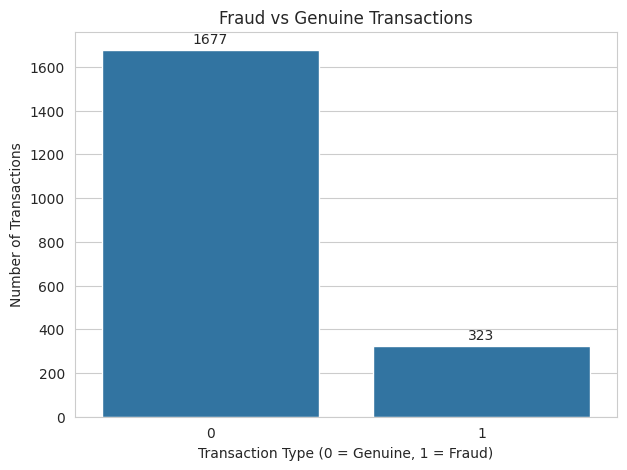

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="is_fraud")

plt.title("Fraud vs Genuine Transactions")
plt.xlabel("Transaction Type (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")

for bar in ax.patches:
    ax.annotate(
        int(bar.get_height()),
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.show()

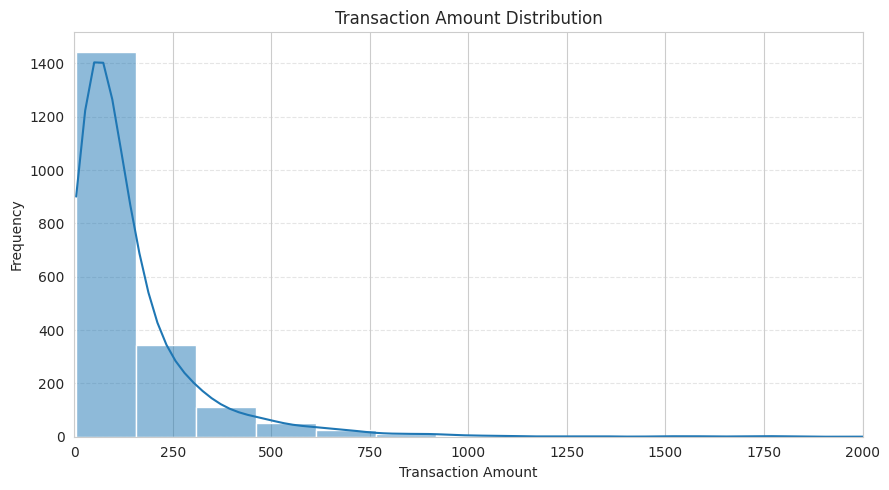

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="amount", bins=30, kde=True)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.xlim(0, 2000)
plt.xticks(range(0, 2001, 250))

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

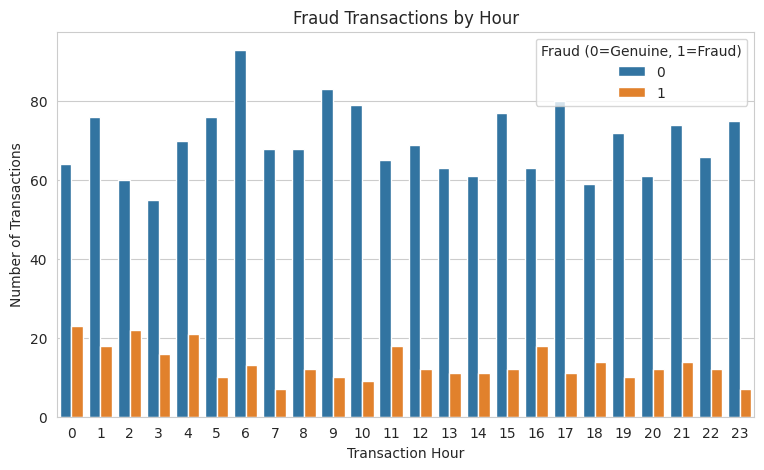

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(data=df, x="hour", hue="is_fraud")

plt.title("Fraud Transactions by Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Transactions")

plt.xticks(range(0, 24))
plt.legend(title="Transaction Type",
           labels=["Genuine (0)", "Fraud (1)"])

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

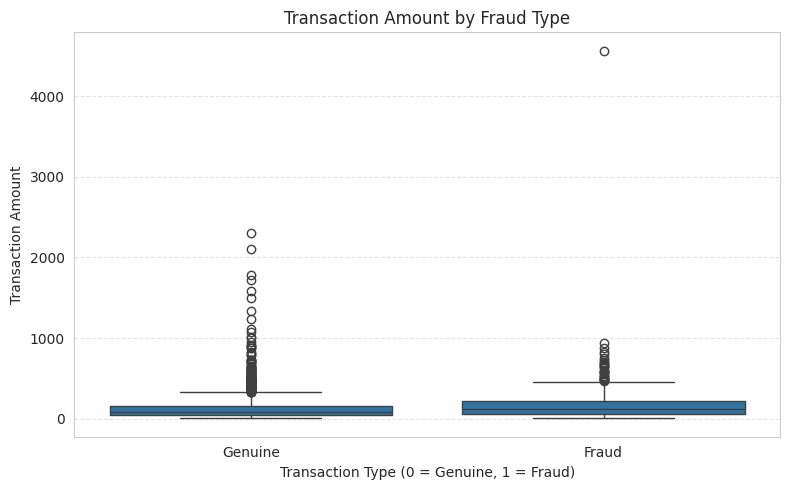

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="is_fraud", y="amount")

plt.title("Transaction Amount by Fraud Type")
plt.xlabel("Transaction Type (0 = Genuine, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Create Financial Transaction Graph**

 1)Identify Unique Accounts

In [ ]:
# Get all unique accounts
unique_accounts = pd.unique(
    pd.concat([df["sender"], df["receiver"]])
)

# Count total accounts
total_accounts = len(unique_accounts)

print("Total Unique Accounts:", total_accounts)
print("First 10 Accounts:", unique_accounts[:10])

Total Unique Accounts: 696
First 10 Accounts: [103 349 271 107  72 189  21 122 215 331]


2) Create Account ID Mapping

In [ ]:
# Create account-to-index mapping
account_to_index = {
    account: index
    for index, account in enumerate(unique_accounts)
}

print("Account Mapping Created Successfully!")
print("Total Mapped Accounts:", len(account_to_index))

# Display first 10 mappings
print("\nFirst 10 Account Mappings:")
for account, index in list(account_to_index.items())[:10]:
    print(account, ":", index)

Account Mapping Created Successfully!
Total Mapped Accounts: 696

First 10 Account Mappings:
103 : 0
349 : 1
271 : 2
107 : 3
72 : 4
189 : 5
21 : 6
122 : 7
215 : 8
331 : 9


3) Convert Sender and Receiver into Node Indices

In [ ]:
df["sender_index"] = df["sender"].map(account_to_index)
df["receiver_index"] = df["receiver"].map(account_to_index)

print("Sender and Receiver Mapping Completed!")

print("\nFirst 10 Transactions:")
display(df[["sender", "receiver",
            "sender_index", "receiver_index"]].head(10))

print("\nMissing Sender Indices:", df["sender_index"].isnull().sum())
print("Missing Receiver Indices:", df["receiver_index"].isnull().sum())

Sender and Receiver Mapping Completed!

First 10 Transactions:


,sender,receiver,sender_index,receiver_index
0,103,509,0,347
1,349,674,1,348
2,271,448,2,349
3,107,452,3,350
4,72,482,4,351
5,189,452,5,350
6,21,369,6,352
7,103,432,0,353
8,122,629,7,354
9,215,689,8,355



Missing Sender Indices: 0
Missing Receiver Indices: 0


4.Create Edge List

In [ ]:
edge_list = df[["sender_index", "receiver_index"]].values

print("Edge List Created Successfully!")
print("Total Edges:", len(edge_list))

print("\nFirst 10 Edges:")
print(edge_list[:10])

Edge List Created Successfully!
Total Edges: 2000

First 10 Edges:
[[  0 347]
 [  1 348]
 [  2 349]
 [  3 350]
 [  4 351]
 [  5 350]
 [  6 352]
 [  0 353]
 [  7 354]
 [  8 355]]


5.Create Financial Transaction Network

In [ ]:
import networkx as nx

# Create a directed graph
G = nx.DiGraph()

# Add account nodes
G.add_nodes_from(unique_accounts)

# Add transaction edges
for sender, receiver in zip(df["sender"], df["receiver"]):
    G.add_edge(sender, receiver)

print("Financial Transaction Graph Created Successfully!")
print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())
print("Graph Type:", type(G).__name__)

Financial Transaction Graph Created Successfully!
Total Nodes: 696
Total Edges: 1979
Graph Type: DiGraph


6.Visualize Financial Transaction Graph

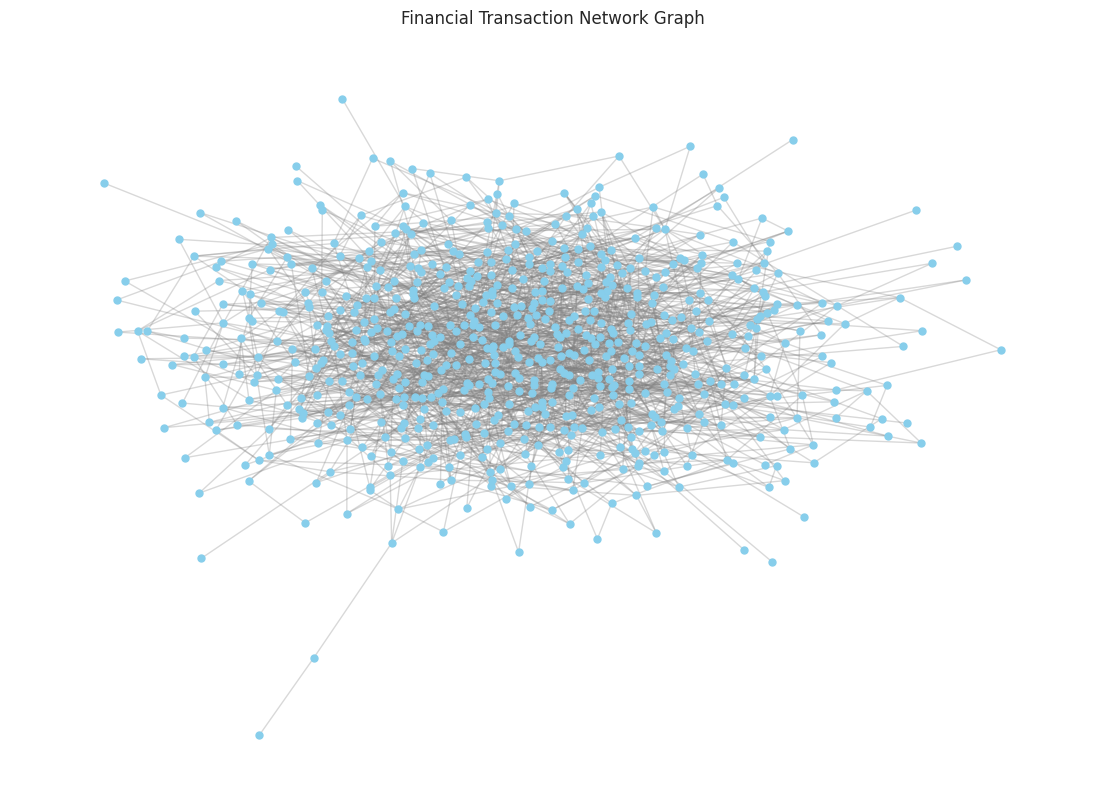

In [ ]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=0.25)

nx.draw_networkx_nodes(
    G, pos,
    node_size=25,
    node_color="skyblue"
)

nx.draw_networkx_edges(
    G, pos,
    edge_color="gray",
    alpha=0.3,
    arrows=False
)

plt.title("Financial Transaction Network Graph")
plt.axis("off")
plt.show()

7.Calculate Account Connections (Degree)

In [ ]:
# Calculate account connections
degree = dict(G.degree())

# Add degree information to a DataFrame
degree_df = pd.DataFrame({
    "Account": list(degree.keys()),
    "Connections": list(degree.values())
})

# Sort accounts by connections
degree_df = degree_df.sort_values(
    by="Connections",
    ascending=False
)

print("Account Connection Analysis Completed!")

print("\nTop 10 Most Connected Accounts:")
display(degree_df.head(10))

print("\nTotal Accounts:", len(degree_df))
print("Maximum Connections:", degree_df["Connections"].max())

Account Connection Analysis Completed!

Top 10 Most Connected Accounts:


,Account,Connections
168,39,14
382,504,14
462,499,13
554,610,13
140,318,12
88,289,12
447,399,12
474,538,12
51,264,12
100,99,11



Total Accounts: 696
Maximum Connections: 14


8.Visualize Top 10 Most Connected Accounts

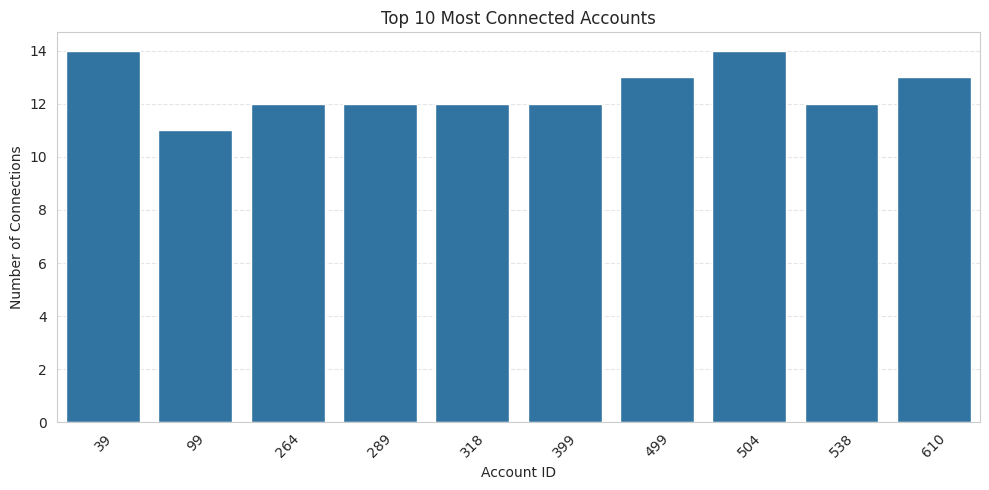

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=degree_df.head(10),
    x="Account",
    y="Connections"
)

plt.title("Top 10 Most Connected Accounts")
plt.xlabel("Account ID")
plt.ylabel("Number of Connections")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Feature Engineering
1.Select Input Features and Target

In [ ]:
# Select input features
feature_columns = [
    "log_amount",
    "hour",
    "account_age_days",
    "previous_transactions",
    "is_night"
]

# Create feature matrix
X = df[feature_columns].copy()

# Create target variable
y = df["is_fraud"].copy()

print("Feature Engineering Started Successfully!")

print("\nFeature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nSelected Features:")
display(X.head())

print("\nTarget Values:")
print(y.head())

Feature Engineering Started Successfully!

Feature Matrix Shape: (2000, 5)
Target Variable Shape: (2000,)

Selected Features:


,log_amount,hour,account_age_days,previous_transactions,is_night
0,4.738858,7,1157,4,0
1,5.004474,12,592,2,0
2,5.171616,3,783,6,1
3,4.928848,13,540,2,0
4,5.343730,13,735,6,0



Target Values:
0    0
1    0
2    1
3    0
4    0
Name: is_fraud, dtype: int64


2.Check Feature Values

In [ ]:
print("Feature Data Types:")
print(X.dtypes)

print("\nMissing Values:")
print(X.isnull().sum())

print("\nFeature Statistics:")
display(X.describe())

Feature Data Types:
log_amount               float64
hour                       int64
account_age_days           int64
previous_transactions      int64
is_night                   int64
dtype: object

Missing Values:
log_amount               0
hour                     0
account_age_days         0
previous_transactions    0
is_night                 0
dtype: int64

Feature Statistics:


,log_amount,hour,account_age_days,previous_transactions,is_night
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,4.495813,11.299000,757.354500,5.984000,0.253500
std,0.990238,6.931856,427.434088,2.417988,0.435123
min,1.695178,0.000000,1.000000,0.000000,0.000000
25%,3.806197,5.000000,394.500000,4.000000,0.000000
50%,4.480264,11.000000,761.000000,6.000000,0.000000
75%,5.140781,17.000000,1120.000000,7.000000,1.000000
max,8.426457,23.000000,1498.000000,17.000000,1.000000


3.Feature Scaling Using StandardScaler

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Scale input features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

print("Feature Scaling Completed Successfully!")

print("\nScaled Feature Shape:", X_scaled.shape)

print("\nFirst 5 Scaled Records:")
display(X_scaled_df.head())

print("\nScaled Feature Statistics:")
display(X_scaled_df.describe())

Feature Scaling Completed Successfully!

Scaled Feature Shape: (2000, 5)

First 5 Scaled Records:


,log_amount,hour,account_age_days,previous_transactions,is_night
0,0.245502,-0.620335,0.935221,-0.820722,-0.582739
1,0.513804,0.101153,-0.386951,-1.648063,-0.582739
2,0.682636,-1.197526,0.060014,0.006619,1.716034
3,0.437413,0.245450,-0.508637,-1.648063,-0.582739
4,0.856490,0.245450,-0.052312,0.006619,-0.582739



Scaled Feature Statistics:


,log_amount,hour,account_age_days,previous_transactions,is_night
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03
mean,8.331114e-16,1.012523e-16,-7.371881e-17,1.110223e-17,-6.217249e-17
std,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00
min,-2.828952e+00,-1.630418e+00,-1.769966e+00,-2.475403e+00,-5.827390e-01
25%,-6.965889e-01,-9.089305e-01,-8.491256e-01,-8.207220e-01,-5.827390e-01
50%,-1.570639e-02,-4.314498e-02,8.530933e-03,6.618726e-03,-5.827390e-01
75%,6.514893e-01,8.226406e-01,8.486366e-01,4.202891e-01,1.716034e+00
max,3.970386e+00,1.688426e+00,1.733205e+00,4.556993e+00,1.716034e+00


4.Prepare Data for Model Training.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data Splitting Completed Successfully!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Data Splitting Completed Successfully!

Training Data Shape: (1600, 5)
Testing Data Shape: (400, 5)

Training Target Distribution:
is_fraud
0    1342
1     258
Name: count, dtype: int64

Testing Target Distribution:
is_fraud
0    335
1     65
Name: count, dtype: int64


5.Apply Feature Scaling Correctly

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create scaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training and Testing Data Scaling Completed!")

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nFirst 5 Scaled Training Records:")
display(pd.DataFrame(
    X_train_scaled,
    columns=feature_columns
).head())

Training and Testing Data Scaling Completed!

Training Data Shape: (1600, 5)
Testing Data Shape: (400, 5)

First 5 Scaled Training Records:


,log_amount,hour,account_age_days,previous_transactions,is_night
0,0.472993,-1.056946,0.711785,1.250017,1.717736
1,0.562858,-0.333753,-0.213858,0.014415,-0.582162
2,0.297696,-0.912308,-0.855230,0.426283,-0.582162
3,-2.038123,-1.201585,1.644476,0.014415,1.717736
4,1.367217,-1.056946,-0.138679,1.661884,1.717736


Prepare Graph Data for GNN Model
1.Convert Features into PyTorch Tensors

In [ ]:
import torch

# Convert features into PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

# Convert target values into tensors
y_train_tensor = torch.tensor(
    y_train.values, dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test.values, dtype=torch.long
)

print("PyTorch Tensor Conversion Completed!")

print("\nTraining Feature Tensor:", X_train_tensor.shape)
print("Testing Feature Tensor:", X_test_tensor.shape)

print("\nTraining Target Tensor:", y_train_tensor.shape)
print("Testing Target Tensor:", y_test_tensor.shape)

PyTorch Tensor Conversion Completed!

Training Feature Tensor: torch.Size([1600, 5])
Testing Feature Tensor: torch.Size([400, 5])

Training Target Tensor: torch.Size([1600])
Testing Target Tensor: torch.Size([400])


2.Load the Transaction Adjacency Matrix

In [ ]:
# Load the existing transaction graph
A_raw = np.load(
    os.path.join(project_path, "adjacency.npy")
)

print("Adjacency Matrix Loaded Successfully!")

print("Adjacency Matrix Shape:", A_raw.shape)
print("Data Type:", A_raw.dtype)
print("Total Connections:", int(A_raw.sum()))

print("Is Matrix Symmetric:",
      np.array_equal(A_raw, A_raw.T))

Adjacency Matrix Loaded Successfully!
Adjacency Matrix Shape: (2000, 2000)
Data Type: float32
Total Connections: 25244
Is Matrix Symmetric: True


3.Prepare Complete Graph Features and Labels

In [ ]:
# Convert all transaction features using the training scaler
X_all_scaled = scaler.transform(X)

# Convert features and labels into tensors
X_all_tensor = torch.tensor(
    X_all_scaled, dtype=torch.float32
)

y_all_tensor = torch.tensor(
    y.values, dtype=torch.long
)

# Create training and testing indices
train_indices = X_train.index.to_numpy()
test_indices = X_test.index.to_numpy()

# Create masks
train_mask = torch.zeros(2000, dtype=torch.bool)
test_mask = torch.zeros(2000, dtype=torch.bool)

train_mask[train_indices] = True
test_mask[test_indices] = True

print("Complete Graph Data Prepared Successfully!")

print("\nFeature Tensor Shape:", X_all_tensor.shape)
print("Target Tensor Shape:", y_all_tensor.shape)

print("Training Transactions:", train_mask.sum().item())
print("Testing Transactions:", test_mask.sum().item())

Complete Graph Data Prepared Successfully!

Feature Tensor Shape: torch.Size([2000, 5])
Target Tensor Shape: torch.Size([2000])
Training Transactions: 1600
Testing Transactions: 400


4.Prepare Normalized Adjacency Matrix

In [ ]:
# Convert adjacency matrix to PyTorch tensor
A_tensor = torch.tensor(A_raw, dtype=torch.float32)

# Calculate node degrees
degree = torch.sum(A_tensor, dim=1)

# Calculate inverse square root of degrees
degree_inv_sqrt = torch.pow(degree, -0.5)

# Create diagonal degree matrix
D_inv_sqrt = torch.diag(degree_inv_sqrt)

# Normalize adjacency matrix
A_norm = D_inv_sqrt @ A_tensor @ D_inv_sqrt

print("Adjacency Matrix Normalization Completed!")

print("Normalized Matrix Shape:", A_norm.shape)
print("Data Type:", A_norm.dtype)
print("Contains NaN:", torch.isnan(A_norm).any().item())

Adjacency Matrix Normalization Completed!
Normalized Matrix Shape: torch.Size([2000, 2000])
Data Type: torch.float32
Contains NaN: False


**Build GNN Model**

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class GCN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(5, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x, adj):

        x = adj @ x

        x = F.relu(self.fc1(x))

        x = F.dropout(
            x,
            p=0.25,
            training=self.training
        )

        x = adj @ x

        return self.fc2(x)


# Create GNN model
model = GCN()

print("GNN Model Created Successfully!")
print(model)

GNN Model Created Successfully!
GCN(
  (fc1): Linear(in_features=5, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=2, bias=True)
)


In [ ]:
import torch.optim as optim

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=0.0001
)

print("Loss Function and Optimizer Configured!")

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function and Optimizer Configured!
Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0.0001
)


**Train the GNN Model**

In [ ]:
# Calculate class weights using training labels
class_counts = torch.bincount(y_all_tensor[train_mask])

class_weights = len(y_train_tensor) / (
    2.0 * class_counts.float()
)

# Weighted loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Train GNN model
epochs = 100
loss_history = []

for epoch in range(epochs):

    model.train()
    optimizer.zero_grad()

    # Forward propagation
    outputs = model(X_all_tensor, A_norm)

    # Calculate training loss only
    loss = criterion(
        outputs[train_mask],
        y_all_tensor[train_mask]
    )

    # Backpropagation
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

print("\nGNN Model Training Completed!")

Epoch [10/100], Loss: 0.6931
Epoch [20/100], Loss: 0.6872
Epoch [30/100], Loss: 0.6815
Epoch [40/100], Loss: 0.6801
Epoch [50/100], Loss: 0.6811
Epoch [60/100], Loss: 0.6782
Epoch [70/100], Loss: 0.6779
Epoch [80/100], Loss: 0.6768
Epoch [90/100], Loss: 0.6769
Epoch [100/100], Loss: 0.6745

GNN Model Training Completed!


**Model Evaluation**

1.Predict Testing Transactions

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Set model to evaluation mode
model.eval()

with torch.no_grad():

    # Generate predictions
    outputs = model(X_all_tensor, A_norm)

    # Select testing transactions
    test_outputs = outputs[test_mask]

    # Predicted classes
    y_pred = torch.argmax(test_outputs, dim=1).numpy()

    # Actual classes
    y_actual = y_all_tensor[test_mask].numpy()

    # Fraud probabilities
    y_probability = torch.softmax(
        test_outputs, dim=1
    )[:, 1].numpy()

print("GNN Predictions Generated Successfully!")

print("\nActual Values:", y_actual[:10])
print("Predicted Values:", y_pred[:10])

GNN Predictions Generated Successfully!

Actual Values: [0 0 0 0 0 0 1 0 1 1]
Predicted Values: [0 1 0 1 0 1 0 0 0 1]


2.Calculate Model Performance Metrics(Accuracy,Precision,Recall,F1-Score,ROC-AUC)

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_actual, y_pred)

precision = precision_score(
    y_actual, y_pred, zero_division=0
)

recall = recall_score(
    y_actual, y_pred, zero_division=0
)

f1 = f1_score(
    y_actual, y_pred, zero_division=0
)

roc_auc = roc_auc_score(
    y_actual, y_probability
)

print("GNN MODEL PERFORMANCE")
print("----------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

GNN MODEL PERFORMANCE
----------------------------
Accuracy : 0.5275
Precision: 0.1593
Recall   : 0.4462
F1 Score : 0.2348
ROC-AUC  : 0.4927


3.Display Confusion Matrix

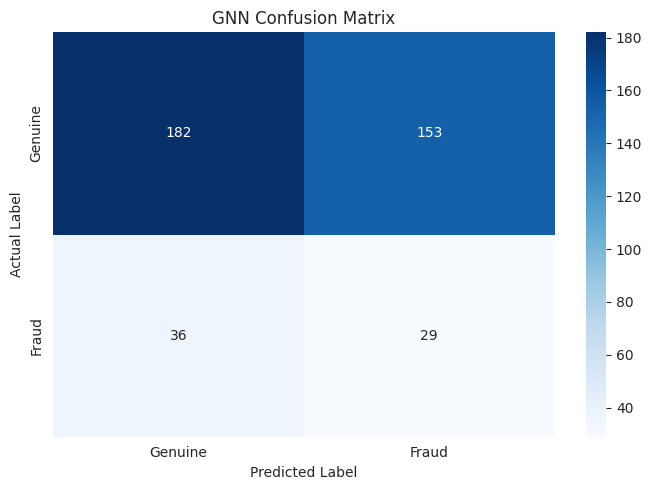

Confusion Matrix:
[[182 153]
 [ 36  29]]


In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.title("GNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

4.Display Classification Report

In [ ]:
print("GNN CLASSIFICATION REPORT")
print("-------------------------------")

print(
    classification_report(
        y_actual,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

GNN CLASSIFICATION REPORT
-------------------------------
              precision    recall  f1-score   support

     Genuine       0.83      0.54      0.66       335
       Fraud       0.16      0.45      0.23        65

    accuracy                           0.53       400
   macro avg       0.50      0.49      0.45       400
weighted avg       0.73      0.53      0.59       400



5.Train Random Forest and XGBoost Models

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_scaled, y_train)

print("Random Forest Training Completed!")
print("XGBoost Training Completed!")

Random Forest Training Completed!
XGBoost Training Completed!


6.Compare Performance of All Three Models

In [ ]:
# Random Forest predictions
rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# XGBoost predictions
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Function to calculate metrics
def calculate_metrics(name, actual, predicted, probability):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probability)
    }

# Compare all three models
results = []

results.append(
    calculate_metrics("GNN", y_actual, y_pred, y_probability)
)

results.append(
    calculate_metrics("Random Forest", y_test, rf_pred, rf_prob)
)

results.append(
    calculate_metrics("XGBoost", y_test, xgb_pred, xgb_prob)
)

metrics_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
display(metrics_df.round(4))

MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,GNN,0.5275,0.1593,0.4462,0.2348,0.4927
1,Random Forest,0.8375,0.5000,0.0308,0.0580,0.5449
2,XGBoost,0.6800,0.2308,0.4154,0.2967,0.6034


7.Visualize Model Performance

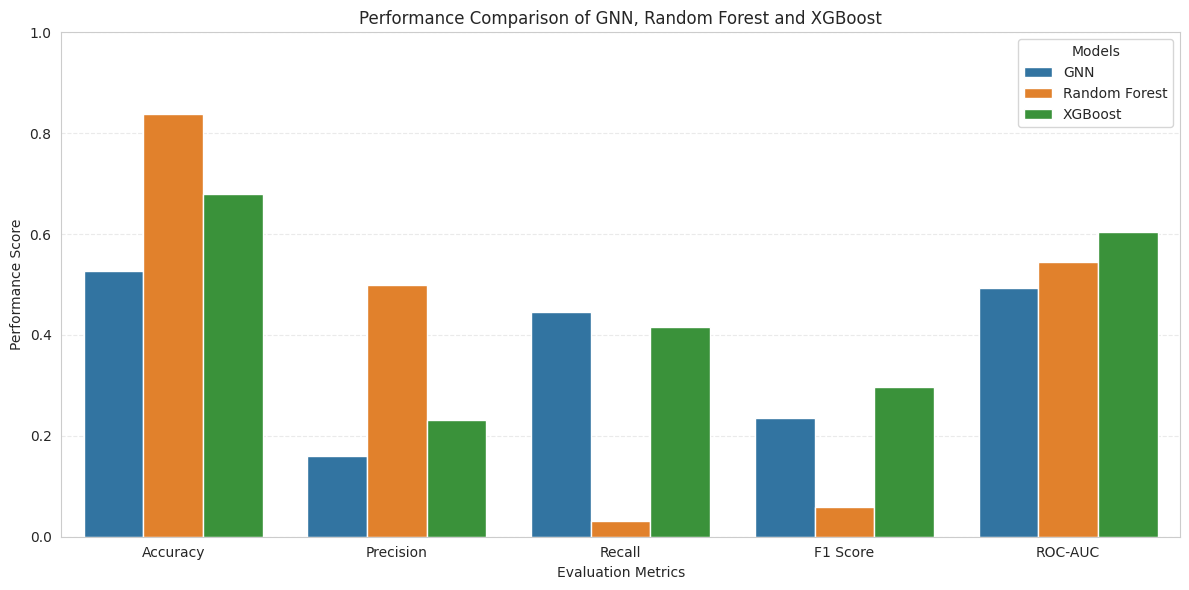

In [ ]:
metrics_plot = metrics_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of GNN, Random Forest and XGBoost")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")

plt.ylim(0, 1)
plt.legend(title="Models")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Save Trained Models**

In [ ]:
import os
import joblib
import torch

# Create project folder
os.makedirs(project_path, exist_ok=True)

# Save GNN model
torch.save(
    model.state_dict(),
    os.path.join(project_path, "gnn_fraud_model.pth")
)

# Save Random Forest
joblib.dump(
    rf_model,
    os.path.join(project_path, "random_forest.pkl")
)

# Save XGBoost
joblib.dump(
    xgb_model,
    os.path.join(project_path, "xgboost_model.pkl")
)

print("All Three Models Saved Successfully!")

All Three Models Saved Successfully!


In [ ]:
import json
import joblib
import numpy as np
import os

# Save the scaler
joblib.dump(scaler, os.path.join(project_path, "scaler.pkl"))

# Save feature names
with open(os.path.join(project_path, "features.json"), "w") as f:
    json.dump(feature_columns, f)

# Save adjacency matrix
np.save(os.path.join(project_path, "adjacency.npy"), A_raw)

# Save model comparison results
metrics_df.to_csv(
    os.path.join(project_path, "model_metrics.csv"),
    index=False
)

print("Scaler saved successfully!")
print("Feature names saved successfully!")
print("Adjacency matrix saved successfully!")
print("Model metrics saved successfully!")

Scaler saved successfully!
Feature names saved successfully!
Adjacency matrix saved successfully!
Model metrics saved successfully!


In [ ]:
import os

print("PROJECT FOLDER FILES")
print("----------------------")

for file in sorted(os.listdir(project_path)):
    file_path = os.path.join(project_path, file)
    print(file, "-", os.path.getsize(file_path), "bytes")

PROJECT FOLDER FILES
----------------------
adjacency.npy - 16000128 bytes
app.py - 8272 bytes
features.json - 79 bytes
gnn_fraud_model.pth - 3565 bytes
gnn_predictions.csv - 148387 bytes
model_metrics.csv - 314 bytes
prediction_history.csv - 1002 bytes
random_forest.pkl - 4950265 bytes
rf_xgb_predictions.csv - 17789 bytes
scaler.pkl - 1039 bytes
transactions.csv - 123294 bytes
xgboost_model.pkl - 161055 bytes


**Save predictions from all three models**

In [ ]:
predictions_df = pd.DataFrame({
    "transaction_id": df.loc[X_test.index, "transaction_id"].values,
    "Actual": y_actual,
    "GNN_Prediction": y_pred,
    "GNN_Probability": y_probability,
    "RF_Prediction": rf_pred,
    "RF_Probability": rf_prob,
    "XGBoost_Prediction": xgb_pred,
    "XGBoost_Probability": xgb_prob
})

predictions_df.to_csv(
    os.path.join(project_path, "test_predictions.csv"),
    index=False
)

print("Test predictions saved successfully!")
display(predictions_df.head(10))

Test predictions saved successfully!


,transaction_id,Actual,GNN_Prediction,GNN_Probability,RF_Prediction,RF_Probability,XGBoost_Prediction,XGBoost_Probability
0,1051,0,0,0.478133,0,0.02,0,0.048370
1,976,0,1,0.504586,0,0.09,0,0.286213
2,1955,0,0,0.387137,0,0.07,0,0.336830
3,1510,0,1,0.529048,0,0.16,0,0.353397
4,334,0,0,0.455592,0,0.12,0,0.251862
5,955,0,1,0.740662,0,0.06,0,0.290314
6,1498,1,0,0.445206,0,0.24,1,0.550914
7,1250,0,0,0.486964,0,0.17,1,0.561551
8,130,1,0,0.467651,0,0.31,1,0.514685
9,340,1,1,0.527688,0,0.03,0,0.418641


In [ ]:
prediction_path = os.path.join(project_path, "test_predictions.csv")

check_predictions = pd.read_csv(prediction_path)

print("Prediction file exists:", os.path.exists(prediction_path))
print("Prediction dataset shape:", check_predictions.shape)
print("Prediction columns:")
print(check_predictions.columns.tolist())

display(check_predictions.head())

Prediction file exists: True
Prediction dataset shape: (400, 8)
Prediction columns:
['transaction_id', 'Actual', 'GNN_Prediction', 'GNN_Probability', 'RF_Prediction', 'RF_Probability', 'XGBoost_Prediction', 'XGBoost_Probability']


,transaction_id,Actual,GNN_Prediction,GNN_Probability,RF_Prediction,RF_Probability,XGBoost_Prediction,XGBoost_Probability
0,1051,0,0,0.478133,0,0.02,0,0.048370
1,976,0,1,0.504586,0,0.09,0,0.286213
2,1955,0,0,0.387137,0,0.07,0,0.336830
3,1510,0,1,0.529048,0,0.16,0,0.353397
4,334,0,0,0.455592,0,0.12,0,0.251862


**Develop the Streamlit web application**

In [ ]:
app_path = os.path.join(project_path, "app.py")

print("Streamlit app exists:", os.path.exists(app_path))

if os.path.exists(app_path):
    print("App file size:", os.path.getsize(app_path), "bytes")
else:
    print("app.py file not found. We need to create it.")

Streamlit app exists: True
App file size: 8272 bytes


1)Check model connections in Streamlit

In [ ]:
with open(app_path, "r") as file:
    app_code = file.read()

required_files = [
    "gnn_fraud_model.pth",
    "random_forest.pkl",
    "xgboost_model.pkl",
    "scaler.pkl",
    "features.json",
    "adjacency.npy"
]

print("CHECKING MODEL FILE REFERENCES")
print("--------------------------------")

for filename in required_files:
    print(filename, ":", filename in app_code)

CHECKING MODEL FILE REFERENCES
--------------------------------
gnn_fraud_model.pth : True
random_forest.pkl : True
xgboost_model.pkl : True
scaler.pkl : True
features.json : True
adjacency.npy : True


2)Check the Streamlit app code

In [ ]:
with open(app_path, "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines, start=1):
    if any(word in line.lower() for word in [
        "torch.load", "joblib.load", "json.load",
        "np.load", "def predict", "st.title"
    ]):
        print(f"Line {i}: {line.rstrip()}")

Line 41:     rf = joblib.load(FOLDER + "/random_forest.pkl")
Line 42:     xgb = joblib.load(FOLDER + "/xgboost_model.pkl")
Line 43:     scaler = joblib.load(FOLDER + "/scaler.pkl")
Line 46:         feature_cols = json.load(f)
Line 49:     adjacency = np.load(FOLDER + "/adjacency.npy")
Line 54:         weights = torch.load(
Line 60:         weights = torch.load(
Line 75: st.title("💳 Financial Fraud Detection System")


3)Check the GNN architecture in app.py

In [ ]:
with open(app_path, "r") as file:
    app_lines = file.readlines()

print("STREAMLIT APP CODE (LINES 1 TO 130)")
print("-----------------------------------")

for i, line in enumerate(app_lines[:130], start=1):
    print(f"{i}: {line.rstrip()}")

STREAMLIT APP CODE (LINES 1 TO 130)
-----------------------------------
1: 
2: import streamlit as st
3: import pandas as pd
4: import numpy as np
5: import joblib
6: import json
7: import torch
8: import torch.nn as nn
9: import torch.nn.functional as F
10: import os
11: from datetime import datetime
12: 
13: # Project folder
14: FOLDER = "/content/drive/MyDrive/Financial_Fraud_Project"
15: 
16: st.set_page_config(
17:     page_title="Financial Fraud Detection",
18:     page_icon="💳",
19:     layout="wide"
20: )
21: 
22: # GNN architecture used during training
23: class GCN(nn.Module):
24:     def __init__(self):
25:         super().__init__()
26:         self.fc1 = nn.Linear(5, 32)
27:         self.fc2 = nn.Linear(32, 2)
28: 
29:     def forward(self, x, adj):
30:         x = adj @ x
31:         x = F.relu(self.fc1(x))
32:         x = F.dropout(x, p=0.25, training=self.training)
33:         x = adj @ x
34:         return self.fc2(x)
35: 
36: 
37: # Load saved models and data
38: @st.

4)Check the prediction logic

In [ ]:
with open(app_path, "r") as file:
    app_lines = file.readlines()

print("STREAMLIT APP CODE (LINES 125 TO END)")
print("--------------------------------------")

for i, line in enumerate(app_lines[124:], start=125):
    print(f"{i}: {line.rstrip()}")

STREAMLIT APP CODE (LINES 125 TO END)
--------------------------------------
125:         )
126: 
127:     with col2:
128:         receiver = st.number_input(
129:             "Receiver Account ID",
130:             min_value=351,
131:             max_value=699,
132:             value=448,
133:             step=1
134:         )
135: 
136:         hour = st.slider(
137:             "Transaction Hour",
138:             min_value=0,
139:             max_value=23,
140:             value=12
141:         )
142: 
143:         previous_transactions = st.number_input(
144:             "Previous Transactions",
145:             min_value=0,
146:             value=5,
147:             step=1
148:         )
149: 
150:     submitted = st.form_submit_button(
151:         "Predict Transaction Risk"
152:     )
153: 
154: 
155: # Prediction
156: if submitted:
157: 
158:     if sender == receiver:
159:         st.error("Sender and receiver IDs must be different.")
160: 
161:     else:
162: 
163:         #

In [ ]:
import shutil
import os

# Create a backup of the original app
shutil.copy2(
    app_path,
    app_path + ".backup"
)

# Read app.py
with open(app_path, "r") as file:
    code = file.read()

old_code = """adj_tensor = torch.tensor(
            new_adj,
            dtype=torch.float32
        )"""

new_code = """# Normalize adjacency matrix
        degree = np.sum(new_adj, axis=1)
        degree_inv_sqrt = np.power(degree, -0.5)
        D_inv_sqrt = np.diag(degree_inv_sqrt)

        new_adj_norm = D_inv_sqrt @ new_adj @ D_inv_sqrt

        # Convert normalized adjacency to tensor
        adj_tensor = torch.tensor(
            new_adj_norm,
            dtype=torch.float32
        )"""

if old_code in code:
    code = code.replace(old_code, new_code, 1)

    with open(app_path, "w") as file:
        file.write(code)

    print("SUCCESS: app.py updated!")
    print("Backup created successfully!")

else:
    print("Old code not found. No changes made.")

SUCCESS: app.py updated!
Backup created successfully!


In [ ]:
with open(app_path, "r") as file:
    code = file.read()

print("Normalization code added:", "new_adj_norm" in code)
print("GNN prediction code present:", "output = gnn" in code)
print("Backup exists:", os.path.exists(app_path + ".backup"))

Normalization code added: True
GNN prediction code present: True
Backup exists: True


In [ ]:
import ast

with open(app_path, "r") as file:
    app_code = file.read()

try:
    ast.parse(app_code)
    print("SUCCESS: No Python syntax errors!")
except SyntaxError as e:
    print("Syntax Error:", e)

SUCCESS: No Python syntax errors!


**Install Streamlit**

In [ ]:
!pip install -q streamlit

1.Start Streamlit application

In [ ]:
!fuser -k 8501/tcp

!streamlit run "/content/drive/MyDrive/Financial_Fraud_Project/app.py" \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /tmp/streamlit.log 2>&1 &

2.Generate dashboard link

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")

print("YOUR FINANCIAL FRAUD DETECTION DASHBOARD:")
print(url)

YOUR FINANCIAL FRAUD DETECTION DASHBOARD:
https://8501-m-s-usc1c7-gkz7gfk9wixq-c.us-central1.prod.r.colab.dev


In [ ]:
import os

print("Files saved in Colab:")
for file in os.listdir("/content"):
    print(file)

Files saved in Colab:
.config
sample_data
